# Severity Label Construction

Builds a severity label (Moderate / Severe / Unknown) for each patient from the data available,
checks that the fields going into it are actually useful before trusting them, then saves one
final dataset with the label attached.

**Why not a standard trauma score:** the usual clinical severity scores (like ISS or KTS) need
vital signs (blood pressure, breathing rate, consciousness level) taken at arrival. This dataset
doesn't have those. So instead, severity is estimated from how much care the patient ended up
needing and how the case turned out - a practical stand-in, not a clinical score, and this
notebook says so plainly rather than pretending otherwise.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kruskal
from statsmodels.stats.proportion import proportions_ztest
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv('Preprocessed Dataset.csv')
df.shape

(6178, 132)

## Step 1 — Build the fields that describe how serious each case was

Only fields about medical care and outcome go in here - how long the patient stayed, whether they
were transferred, what treatment they got, how they were discharged. Money, occupation, and similar
fields are deliberately left out, since they describe circumstances, not medical severity.

In [2]:
# ward days -> total_days
ward_cols = ['Number of days in first ward', 'Number of days in Second ward', 'Number of days in Third ward']

for c in ward_cols:
    early_mask = df[c + '_missing_reason'] == 'early_discharge'  # "no extra days needed"
    df[c] = pd.to_numeric(df[c], errors='coerce')
    df.loc[early_mask, c] = df.loc[early_mask, c].fillna(0)

# min_count=1: a row with all three wards genuinely unrecorded stays NaN, not a silent 0
df['total_days'] = df[ward_cols].sum(axis=1, skipna=True, min_count=1)

# wards stayed: no ward recorded = 0 wards
df['wards_stayed'] = pd.to_numeric(df['Number of Wards Stayed'], errors='coerce').fillna(0)

In [3]:
# transfer fields: yes/no -> 1/0, plus whether extra support was needed during transfer
df['transfer_flag'] = df['Transfer To Next Hospital'].map({'yes': 1, 'no': 0})
df['transfer_treatment_flag'] = df['Treatment During Tranfer'].map({'yes': 1, 'no': 0})

def transfer_support(x):
    # genuinely unrecorded (only 1 row) is unknown, not "no support needed" - don't guess
    if pd.isna(x):
        return np.nan
    return 0 if 'without any support' in str(x) else 1

df['transfer_support_flag'] = df['State of Transfer'].apply(transfer_support)

In [4]:
# investigation intensity: imaging type as a candidate severity proxy (checked in Step 6)
investigation_map = {'ct scan': 2, 'mri scan': 2, 'ultrasound scan': 2, 'x-ray': 1, 'others': 0}
# no fillna(0) - a genuinely unrecorded investigation is unknown, not "no scan done"
df['investigation_score'] = df['Investigation Done'].map(investigation_map)

In [5]:
# management done: rank severity (text is already lowercase from the cleaning notebook)
mgmt_rank = {
    'wound cleaning and dressing': 0, 'only medicine and discharge': 0, 'no other management': 0,
    'wound suturing': 1, 'wound debridement': 1,
    'informed to jmo / police': 1,   # medico-legal reporting trigger, not paperwork -> nonzero
    'fracture stabilization': 2,
    'surgery': 3,
}
# this phrase means "we don't know what management was given", not "no management was given"
MGMT_MISSING_PHRASE = 'early discharge/ data entry staff missed to enter'

def clean_mgmt(x):
    return np.nan if pd.isna(x) or x == MGMT_MISSING_PHRASE else x

m1 = df['Management Name 1'].apply(clean_mgmt).map(mgmt_rank)
m2 = df['Management Name 2'].apply(clean_mgmt).map(mgmt_rank)
# take the more severe of the two - no fillna(0): if both unmapped/missing, stays NaN
df['management_score'] = pd.concat([m1, m2], axis=1).max(axis=1)

In [6]:
# discharge outcome: the one direct clinical judgment already in the data
outcome_map = {'complete recovery': 0, 'partial recovery': 1, 'further interventions': 3}
df['outcome_score'] = df['Discharge Outcome'].map(outcome_map)  # 'others' -> NaN on purpose

## Step 2 — Check the fields actually make sense before using them

Two checks on the fields from Step 1:
- Do any two fields just repeat the same information? (checked with a correlation number - closer
  to 1 means "these two move together almost every time")
- Does a field actually vary, or does almost every patient have the same value, in which case it
  can't tell patients apart?

In [7]:
ingredient_cols = ['total_days', 'wards_stayed', 'transfer_flag', 'transfer_treatment_flag',
                    'transfer_support_flag', 'investigation_score', 'management_score', 'outcome_score']

correlation = df[ingredient_cols].corr(method='spearman')  # works with skewed, non-numeric-scale data
correlation.round(2)

,total_days,wards_stayed,transfer_flag,transfer_treatment_flag,transfer_support_flag,investigation_score,management_score,outcome_score
total_days,1.00,0.97,0.05,0.01,-0.00,-0.18,0.26,0.03
wards_stayed,0.97,1.00,0.05,0.02,-0.00,-0.16,0.24,0.03
transfer_flag,0.05,0.05,1.00,0.64,0.28,-0.02,0.03,0.04
transfer_treatment_flag,0.01,0.02,0.64,1.00,0.26,-0.02,0.02,0.02
transfer_support_flag,-0.00,-0.00,0.28,0.26,1.00,-0.03,-0.01,0.03
investigation_score,-0.18,-0.16,-0.02,-0.02,-0.03,1.00,-0.10,0.01
management_score,0.26,0.24,0.03,0.02,-0.01,-0.10,1.00,0.05
outcome_score,0.03,0.03,0.04,0.02,0.03,0.01,0.05,1.00


In [8]:
# a pair moving together above 0.7 is basically one signal counted twice
redundant_pairs = [(a, b, round(correlation.loc[a, b], 2))
                    for i, a in enumerate(ingredient_cols) for b in ingredient_cols[i+1:]
                    if abs(correlation.loc[a, b]) >= 0.7]
print('Fields repeating the same information:', redundant_pairs)

Fields repeating the same information: [('total_days', 'wards_stayed', np.float64(0.97))]


In [9]:
# a field where almost every patient has the same value can't tell patients apart
for col in ingredient_cols:
    top_share = df[col].value_counts(normalize=True, dropna=True).iloc[0]
    flag = '  <- barely varies' if top_share >= 0.95 else ''
    print(f'{col:25s} most common value covers: {top_share:.0%}{flag}')

total_days                most common value covers: 46%
wards_stayed              most common value covers: 46%
transfer_flag             most common value covers: 88%
transfer_treatment_flag   most common value covers: 95%
transfer_support_flag     most common value covers: 99%  <- barely varies
investigation_score       most common value covers: 55%
management_score          most common value covers: 69%
outcome_score             most common value covers: 86%


`total_days` and `wards_stayed` move together almost perfectly (0.97) - both are really saying
"how long was this patient in hospital." Keeping both would let length-of-stay count twice and
dominate the final score. `total_days` is more precise, so `wards_stayed` is dropped.

In [10]:
ingredient_cols.remove('wards_stayed')

## Step 3 — Combine everything into one severity number per patient

The fields are grouped into four themes (length of stay, escalation of care, treatment given,
outcome), and each theme is put on the same scale before adding them together - otherwise a theme
with big numbers (days in hospital, 0-29) would automatically outweigh a theme with small numbers
(outcome, 0-3), even if it isn't actually more important.

If a patient is missing data in even one of the four themes, they're set aside as Unknown rather
than guessed at.

In [11]:
def zscore(s):
    return (s - s.mean()) / s.std()

def build_severity_score(df, ingredient_cols):
    """Combines the fields into one severity number. Called again later if the field list changes."""
    df['domain_LOS']          = df['total_days']
    df['domain_escalation']   = df['transfer_flag'] + df['transfer_treatment_flag'] + df['transfer_support_flag']
    # plain '+' (not .sum) so ANY missing ingredient makes the whole domain NaN, matching
    # domain_escalation's behaviour - this is what lets label_unknown catch real missingness
    intervention_cols = [c for c in ['investigation_score', 'management_score'] if c in ingredient_cols]
    df['domain_intervention'] = df[intervention_cols[0]]
    for c in intervention_cols[1:]:
        df['domain_intervention'] = df['domain_intervention'] + df[c]
    df['domain_outcome']      = df['outcome_score']

    raw_domains = ['domain_LOS', 'domain_escalation', 'domain_intervention', 'domain_outcome']
    df['label_unknown'] = df[raw_domains].isna().sum(axis=1) >= 1

    for d in raw_domains:
        df['z_' + d.replace('domain_', '')] = zscore(df[d])
    z_cols = ['z_LOS', 'z_escalation', 'z_intervention', 'z_outcome']
    df['composite'] = df[z_cols].sum(axis=1, min_count=1)
    return df

df = build_severity_score(df, ingredient_cols)

## Step 4 — Split patients into Moderate and Severe

Groups patients into two clusters based on the severity number, then checks the histogram below -
if it's one smooth hump rather than two separate groups, splitting it in two would be arbitrary,
not a real pattern. A separation score (0 = no real separation, 1 = perfectly separated groups)
confirms which case this is; if the groups aren't clearly separate, the notebook falls back to a
simple midpoint split and says so, instead of pretending the split is more meaningful than it is.

Separation score (0-1, higher = clearer split): 0.631


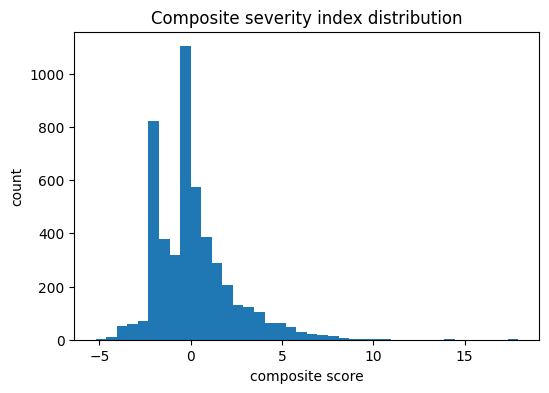

severity_label
Moderate    3790
Unknown     1268
Severe      1120
Name: count, dtype: int64

In [12]:
def split_moderate_severe(df):
    """Groups patients into Moderate/Severe based on their severity number. Unknown rows are left as-is."""
    scored = df[~df['label_unknown']].copy()
    X = scored['composite'].dropna().values.reshape(-1, 1)

    km = KMeans(n_clusters=2, n_init=10, random_state=42)
    cluster_ids = km.fit_predict(X)
    sil = silhouette_score(X, cluster_ids)
    print('Separation score (0-1, higher = clearer split):', round(sil, 3))

    severe_cluster = np.argmax(km.cluster_centers_)
    labels = np.where(cluster_ids == severe_cluster, 'Severe', 'Moderate')
    if sil < 0.15:
        print('Groups not clearly separated - using a simple midpoint split instead')
        labels = np.where(X.flatten() >= np.median(X), 'Severe', 'Moderate')

    scored.loc[scored['composite'].notna(), 'severity_label'] = labels
    df['severity_label'] = 'Unknown'
    df.loc[scored.index, 'severity_label'] = scored['severity_label']
    df.loc[df['label_unknown'], 'severity_label'] = 'Unknown'
    return df

df = split_moderate_severe(df)
plt.figure(figsize=(6, 4))
plt.hist(df.loc[~df['label_unknown'], 'composite'].dropna(), bins=40)
plt.title('Composite severity index distribution')
plt.xlabel('composite score')
plt.ylabel('count')
plt.show()
df['severity_label'].value_counts()

## Step 5 — Correct a few injury types the score gets wrong

Some injuries are dangerous but get treated and resolved quickly, so they score low on
length-of-stay even though they should count as Severe. Instead of assuming which injury types
these are, each candidate is checked against the data: does it have enough real cases (at least 15),
and is its Moderate rate actually different from the dataset's overall rate in a way unlikely to be
chance? Only types passing both checks get corrected - a handful of cases pointing one way isn't
enough evidence either way.

In [13]:
df['injury_type_clean'] = df['Type of injury No 1']  # already lowercased/stripped in the cleaning notebook

CRITICAL_CANDIDATES = {
    'spinal cord injury', 'pneumothorax', 'pericardial effusion',
    'ich', 'sdh', 'kidney injury', 'bowel injury', 'spleen injury'
}
MIN_SAMPLE = 15
SIGNIFICANCE = 0.05

overall_moderate_rate = (df['severity_label'] == 'Moderate').mean()
rows = []
for inj in CRITICAL_CANDIDATES:
    sub = df[df['injury_type_clean'] == inj]
    n, mod_count = len(sub), (sub['severity_label'] == 'Moderate').sum()
    p = proportions_ztest(mod_count, n, overall_moderate_rate)[1] if n >= MIN_SAMPLE else float('nan')
    rows.append({'injury_type': inj, 'n': n, 'moderate_rate': round(mod_count / n, 2) if n else np.nan, 'p_value': p})

evidence = pd.DataFrame(rows).sort_values('n', ascending=False)
evidence

,injury_type,n,moderate_rate,p_value
7,spinal cord injury,45,0.53,0.281255
4,pericardial effusion,34,0.44,0.043043
2,sdh,28,0.39,0.016837
3,pneumothorax,8,0.50,NaN
6,ich,6,0.33,NaN
0,spleen injury,4,0.50,NaN
5,kidney injury,4,0.25,NaN
1,bowel injury,3,0.33,NaN


In [14]:
override_injuries = evidence[(evidence['n'] >= MIN_SAMPLE) & (evidence['p_value'] < SIGNIFICANCE)]['injury_type'].tolist()
print('Overriding to Severe:', override_injuries)
print('Not enough evidence, left as-is:', [i for i in CRITICAL_CANDIDATES if i not in override_injuries])

override_mask = df['injury_type_clean'].isin(override_injuries)
df.loc[override_mask, 'severity_label'] = 'Severe'
print('Rows overridden:', override_mask.sum())
df['severity_label'].value_counts()

Overriding to Severe: ['pericardial effusion', 'sdh']
Not enough evidence, left as-is: ['spleen injury', 'bowel injury', 'pneumothorax', 'kidney injury', 'ich', 'spinal cord injury']
Rows overridden: 62


severity_label
Moderate    3764
Unknown     1239
Severe      1175
Name: count, dtype: int64

## Step 6 — Check each field is actually pulling its weight

Now that patients are labeled, check whether each field genuinely differs between Moderate and
Severe patients, or whether it makes no real difference. A field can look "statistically real" with
this many patients even when the actual difference is tiny, so what matters is the size of the gap,
not just whether it's technically nonzero. Roughly: below 0.01 = no real difference, 0.01-0.06 =
small, 0.06+ = a difference worth keeping.

This checks the fields against the label built from them, so some relationship is expected - the
real, independent check is Step 8, using injury type, which was never used to build the label.

In [15]:
labeled = df[df['severity_label'].isin(['Moderate', 'Severe'])]

def effect_size(h_stat, n, k=2):
    return (h_stat - k + 1) / (n - k)

results = []
for col in ingredient_cols:
    groups = [g[col].dropna().values for _, g in labeled.groupby('severity_label')]
    h, p = kruskal(*groups)
    n = sum(len(g) for g in groups)
    results.append({'field': col, 'p_value': p, 'size_of_difference': round(effect_size(h, n), 3)})

pd.DataFrame(results).sort_values('size_of_difference', ascending=False)

,field,p_value,size_of_difference
1,transfer_flag,3.979932e-225,0.208
2,transfer_treatment_flag,4.427753e-165,0.152
0,total_days,2.048843e-142,0.131
5,management_score,1.318350e-139,0.128
6,outcome_score,8.823454e-113,0.103
3,transfer_support_flag,3.936548e-33,0.029
4,investigation_score,4.087960e-09,0.007


`investigation_score` shows almost no real difference between Moderate and Severe, despite sounding
useful (a CT/MRI scan suggests the doctor was worried). It's not pulling its weight, so it's dropped,
and the severity number and grouping are rebuilt without it.

In [16]:
ingredient_cols.remove('investigation_score')

df = build_severity_score(df, ingredient_cols)
df = split_moderate_severe(df)
df.loc[override_mask, 'severity_label'] = 'Severe'  # put the injury-type correction back
df['severity_label'].value_counts()

Separation score (0-1, higher = clearer split): 0.649


severity_label
Moderate    4792
Severe      1373
Unknown       13
Name: count, dtype: int64

## Step 7 — Check the label against discharge outcome

Patients who needed "Further Interventions" after discharge should be mostly labeled Severe. If
they aren't, something in Step 3's weighting is off, and that's what needs revisiting - not this
result forced to look right.

In [17]:
pd.crosstab(df['Discharge Outcome'], df['severity_label'], normalize='index').round(2)

severity_label,Moderate,Severe,Unknown
Discharge Outcome,,,
complete recovery,0.89,0.11,0.01
further interventions,0.03,0.97,0.00
others,0.00,0.00,1.00
partial recovery,0.81,0.19,0.00


## Step 8 — Check the label against injury type (the real test)

Injury type was never used to build the label - only a small correction list in Step 5 touches it,
and only for two injury types. So this comparison is a genuine check, not circular: dangerous injury
types (spinal cord injury, pneumothorax, internal organ injuries) should still come out mostly
Severe here, on their own, without having been told to.

In [18]:
pd.crosstab(df['injury_type_clean'], df['severity_label'], normalize='index').round(2).sort_values('Severe', ascending=False)

severity_label,Moderate,Severe,Unknown
injury_type_clean,,,
pericardial effusion,0.00,1.00,0.00
lung injury,0.00,1.00,0.00
sdh,0.00,1.00,0.00
kidney injury,0.25,0.75,0.00
ich,0.33,0.67,0.00
fracture,0.60,0.39,0.00
bowel injury,0.67,0.33,0.00
contusion,0.71,0.29,0.00
amputation,0.71,0.29,0.00


## Step 9 — Check the group sizes, and list what must never be used as a prediction feature

If Severe ends up under about 10% of patients, that's worth knowing now - a model trained on this
label later would need extra handling for that imbalance.

Also listing every column that went into building this label. None of these can ever be used as an
input feature for a future model that predicts severity - if they were, the model would just be
reading the answer off the label instead of learning to predict it.

In [19]:
counts = df['severity_label'].value_counts()
print(counts)
print((counts / counts.sum() * 100).round(1))

severity_label
Moderate    4792
Severe      1373
Unknown       13
Name: count, dtype: int64
severity_label
Moderate    77.6
Severe      22.2
Unknown      0.2
Name: count, dtype: float64


In [20]:
LABEL_CONSTRUCTION_COLUMNS = [
    'Number of days in first ward', 'Number of days in Second ward', 'Number of days in Third ward',
    'Number of Wards Stayed',
    'Transfer To Next Hospital', 'Treatment During Tranfer', 'State of Transfer',
    'Investigation Done', 'Management Name 1', 'Management Name 2', "Type of injury No 1",
    'Discharge Outcome'
]
for c in LABEL_CONSTRUCTION_COLUMNS:
    print(' -', c)

 - Number of days in first ward
 - Number of days in Second ward
 - Number of days in Third ward
 - Number of Wards Stayed
 - Transfer To Next Hospital
 - Treatment During Tranfer
 - State of Transfer
 - Investigation Done
 - Management Name 1
 - Management Name 2
 - Type of injury No 1
 - Discharge Outcome


## Step 10 — Check the grouping actually repeats

The Moderate/Severe split so far comes from one clustering run. If a different random sample of the
same patients would have drawn the group boundary somewhere else, the split isn't a reliable
pattern - it's just one run's guess. Checked by re-clustering many resampled versions of the data
and seeing how often each patient lands on the same side.

In [21]:
rng = np.random.default_rng(0)
scored_idx = df.index[~df['label_unknown']]
scores = df.loc[scored_idx, 'composite'].dropna()
X_all = scores.values.reshape(-1, 1)

N_RUNS = 50
severe_votes = np.zeros(len(scores))

for run in range(N_RUNS):
    sample = X_all[rng.integers(0, len(X_all), len(X_all))]  # resample patients with replacement
    km = KMeans(n_clusters=2, n_init=10, random_state=run).fit(sample)
    severe_cluster = np.argmax(km.cluster_centers_)
    severe_votes += (km.predict(X_all) == severe_cluster)

severe_vote_rate = severe_votes / N_RUNS
repeated_label = np.where(severe_vote_rate >= 0.5, 'Severe', 'Moderate')

agreement = (repeated_label == df.loc[scores.index, 'severity_label'].values).mean()
consistent_share = ((severe_vote_rate >= 0.95) | (severe_vote_rate <= 0.05)).mean()

print(f'Patients who get the same label as before, across {N_RUNS} reruns: {agreement:.1%}')
print(f'Patients with a clear-cut vote (95%+ one way): {consistent_share:.1%}')

Patients who get the same label as before, across 50 reruns: 99.2%
Patients with a clear-cut vote (95%+ one way): 100.0%


## Step 11 — Remove Unknown rows

Unknown rows are cases the label can't confidently call, not a real severity level - they're dropped
here so the saved dataset only contains patients who actually have a Moderate or Severe label.

In [22]:
before = len(df)
df = df[df['severity_label'] != 'Unknown'].copy()
print(f'Dropped {before - len(df)} Unknown rows, {len(df)} remaining')

Dropped 13 Unknown rows, 6165 remaining


## Step 12 — Save the result

Drop everything that went into building the label: the raw source columns (`LABEL_CONSTRUCTION_COLUMNS`,
listed in Step 9) and every engineered column this notebook built along the way (ingredient scores,
domains, z-scores, `composite`). Only `severity_label` is kept as the added column - the final file
is the original dataset plus one new label, nothing that could leak into a future model as a feature.

In [23]:
engineered_cols = [
    'total_days', 'wards_stayed', 'transfer_flag', 'transfer_treatment_flag', 'transfer_support_flag',
    'investigation_score', 'management_score', 'outcome_score',
    'domain_LOS', 'domain_escalation', 'domain_intervention', 'domain_outcome',
    'z_LOS', 'z_escalation', 'z_intervention', 'z_outcome',
    'composite', 'label_unknown', 'injury_type_clean',
]
cols_to_drop = engineered_cols + LABEL_CONSTRUCTION_COLUMNS
df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

df.to_csv('Cleaned Dataset with Severity.csv', index=False)
print(f'{len(df.columns)} columns saved')
df['severity_label'].value_counts()

121 columns saved


severity_label
Moderate    4792
Severe      1373
Name: count, dtype: int64